In [1]:
# Part 1: Generate make_moons dataset

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

np.random.seed(42)

X, y = make_moons(
    n_samples=500,
    noise=0.1,
    random_state=42
)

y = y.reshape(-1, 1).astype(float)

print("Dataset: make_moons")
print(f"X shape = {X.shape}   (n_samples, n_features)")
print(f"y shape = {y.shape}   (n_samples, 1)")

Dataset: make_moons
X shape = (500, 2)   (n_samples, n_features)
y shape = (500, 1)   (n_samples, 1)


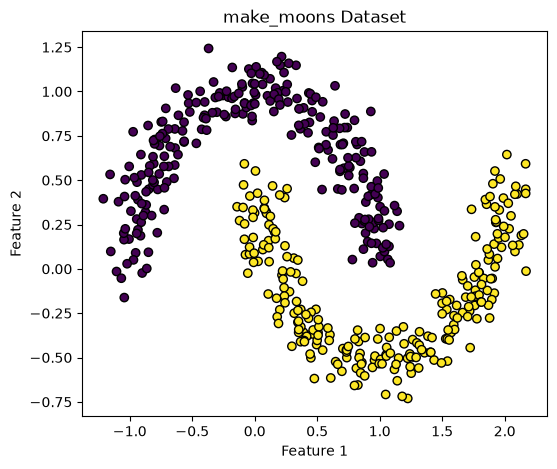

In [2]:
plt.figure(figsize=(6, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y.ravel(),
    edgecolors="k"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("make_moons Dataset")
plt.show()

In [3]:
# Part 2: Activation functions

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))


def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)


def relu(z):
    return np.maximum(0.0, z)


def relu_prime(z):
    return (z > 0).astype(float)


ACTIVATIONS = {
    "sigmoid": (sigmoid, sigmoid_prime),
    "relu":    (relu, relu_prime),
}

In [4]:
z_test = np.array([-2, -1, 0, 1, 2])

print("z =", z_test)
print("Sigmoid =", sigmoid(z_test))
print("Sigmoid derivative =", sigmoid_prime(z_test))
print("ReLU =", relu(z_test))
print("ReLU derivative =", relu_prime(z_test))

z = [-2 -1  0  1  2]
Sigmoid = [0.11920292 0.26894142 0.5        0.73105858 0.88079708]
Sigmoid derivative = [0.10499359 0.19661193 0.25       0.19661193 0.10499359]
ReLU = [0. 0. 0. 1. 2.]
ReLU derivative = [0. 0. 0. 1. 1.]


In [5]:
# Part 3A: Weight initialization

def init_weights(layer_sizes, act_name):
    Ws, bs = [], []

    for i in range(len(layer_sizes) - 1):

        fan_in = layer_sizes[i]
        fan_out = layer_sizes[i + 1]

        # Output layer uses sigmoid
        if i == len(layer_sizes) - 2:

            # Xavier initialization
            W = np.random.randn(fan_in, fan_out) * np.sqrt(1.0 / fan_in)

        elif act_name == "relu":

            # He initialization for ReLU
            W = np.random.randn(fan_in, fan_out) * np.sqrt(2.0 / fan_in)

        else:

            # Xavier initialization for sigmoid
            W = np.random.randn(fan_in, fan_out) * np.sqrt(1.0 / fan_in)

        b = np.zeros((1, fan_out))

        Ws.append(W)
        bs.append(b)

    return Ws, bs

In [6]:
# Part 3B: Forward propagation

def forward(X, Ws, bs, act):

    zs = []
    hs = [X]

    h = X
    L = len(Ws)

    for i, (W, b) in enumerate(zip(Ws, bs)):

        z = h @ W + b

        # Output layer always uses sigmoid
        if i == L - 1:
            h = sigmoid(z)
        else:
            h = act(z)

        zs.append(z)
        hs.append(h)

    return hs, zs

In [7]:
# Part 3C: Mean Squared Error

def mse_loss(y_pred, y_true):
    return np.mean((y_pred - y_true) ** 2)


def mse_grad(y_pred, y_true):

    n = y_true.shape[0]

    return 2.0 * (y_pred - y_true) / (
        n * y_true.shape[1]
    )

In [8]:
# Part 3D: Backward propagation

def backward(hs, zs, Ws, y_true, act_prime):

    L = len(Ws)

    dWs = [None] * L

    # Output layer
    delta = (
        mse_grad(hs[-1], y_true)
        * sigmoid_prime(zs[-1])
    )

    # Backpropagate
    for k in reversed(range(L)):

        dWs[k] = hs[k].T @ delta

        if k > 0:

            delta = (
                delta @ Ws[k].T
            ) * act_prime(zs[k - 1])

    return dWs

In [9]:
# Part 4: Gradient checking

def grad_check(
    act_name,
    layer_sizes,
    X,
    y,
    eps=1e-5
):

    act, act_prime = ACTIVATIONS[act_name]

    Ws, bs = init_weights(
        layer_sizes,
        act_name
    )

    hs, zs = forward(
        X,
        Ws,
        bs,
        act
    )

    dWs = backward(
        hs,
        zs,
        Ws,
        y,
        act_prime
    )

    # Check first weight matrix
    k = 0

    W = Ws[k]

    max_rel_err = 0.0

    for _ in range(5):

        i = np.random.randint(W.shape[0])
        j = np.random.randint(W.shape[1])

        orig = W[i, j]

        # f(x + eps)
        W[i, j] = orig + eps

        hp, _ = forward(
            X,
            Ws,
            bs,
            act
        )

        lp = mse_loss(
            hp[-1],
            y
        )

        # f(x - eps)
        W[i, j] = orig - eps

        hm, _ = forward(
            X,
            Ws,
            bs,
            act
        )

        lm = mse_loss(
            hm[-1],
            y
        )

        # Restore
        W[i, j] = orig

        # Numerical gradient
        num = (lp - lm) / (2 * eps)

        # Analytical gradient
        ana = dWs[k][i, j]

        rel = abs(num - ana) / (
            abs(num) + abs(ana) + 1e-12
        )

        max_rel_err = max(
            max_rel_err,
            rel
        )

    return max_rel_err

In [10]:
# Gradient check

small_layer_sizes = [2, 5, 5, 1]

sigmoid_error = grad_check(
    "sigmoid",
    small_layer_sizes,
    X,
    y
)

relu_error = grad_check(
    "relu",
    small_layer_sizes,
    X,
    y
)

print(
    f"Sigmoid max relative error = {sigmoid_error:.2e}"
)

print(
    f"ReLU max relative error = {relu_error:.2e}"
)

Sigmoid max relative error = 8.62e-09
ReLU max relative error = 6.31e-11


In [12]:
# Part 5A: Training experiment

def run_experiment(
    act_name,
    layer_sizes,
    X,
    y,
    n_steps=200,
    lr=0.05
):

    act, act_prime = ACTIVATIONS[act_name]

    Ws, bs = init_weights(
        layer_sizes,
        act_name
    )

    grad_norm_history = []
    loss_history = []

    for step in range(n_steps):

        # Forward
        hs, zs = forward(
            X,
            Ws,
            bs,
            act
        )

        # Loss
        loss = mse_loss(
            hs[-1],
            y
        )

        # Backward
        dWs = backward(
            hs,
            zs,
            Ws,
            y,
            act_prime
        )

        # Gradient norms
        norms = np.array([
            np.linalg.norm(dW)
            for dW in dWs
        ])

        grad_norm_history.append(norms)
        loss_history.append(loss)

        # Gradient descent
        for k in range(len(Ws)):

            Ws[k] -= lr * dWs[k]

    return (
        np.array(grad_norm_history),
        np.array(loss_history)
    )

In [13]:
# Part 5B: 10-hidden-layer network

layer_sizes = [2] + [16] * 10 + [1]

print("Layer sizes:")
print(layer_sizes)

Layer sizes:
[2, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 1]


In [14]:
sig_grad, sig_loss = run_experiment(
    "sigmoid",
    layer_sizes,
    X,
    y,
    n_steps=200,
    lr=0.05
)

print(
    f"Sigmoid final loss = {sig_loss[-1]:.6f}"
)

Sigmoid final loss = 0.250001


In [15]:
relu_grad, relu_loss = run_experiment(
    "relu",
    layer_sizes,
    X,
    y,
    n_steps=200,
    lr=0.05
)

print(
    f"ReLU final loss = {relu_loss[-1]:.6f}"
)

ReLU final loss = 0.073198


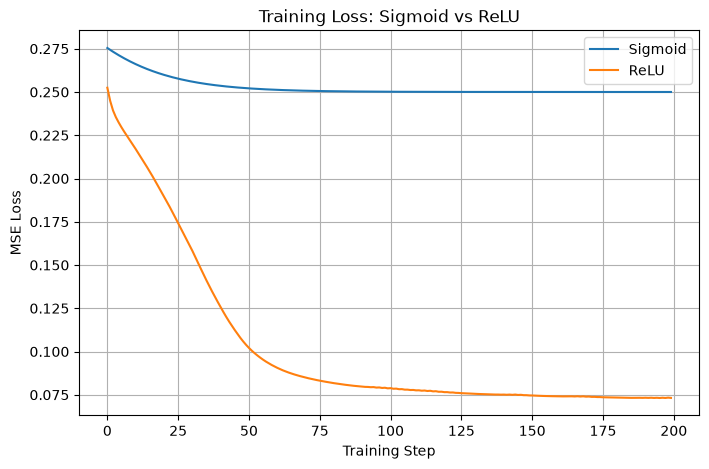

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    sig_loss,
    label="Sigmoid"
)

plt.plot(
    relu_loss,
    label="ReLU"
)

plt.xlabel("Training Step")
plt.ylabel("MSE Loss")
plt.title("Training Loss: Sigmoid vs ReLU")
plt.legend()
plt.grid(True)

plt.show()

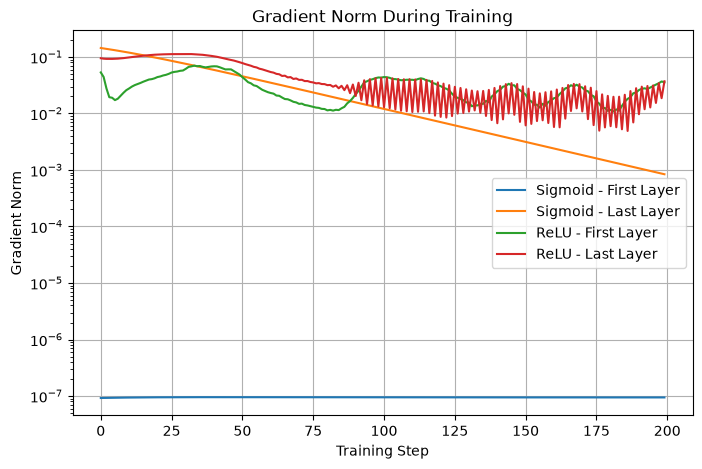

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    sig_grad[:, 0],
    label="Sigmoid - First Layer"
)

plt.plot(
    sig_grad[:, -1],
    label="Sigmoid - Last Layer"
)

plt.plot(
    relu_grad[:, 0],
    label="ReLU - First Layer"
)

plt.plot(
    relu_grad[:, -1],
    label="ReLU - Last Layer"
)

plt.yscale("log")

plt.xlabel("Training Step")
plt.ylabel("Gradient Norm")
plt.title("Gradient Norm During Training")

plt.legend()
plt.grid(True)

plt.show()

In [18]:
# Part 6: Depth experiment

depths = [2, 5, 10, 15, 20]
n_runs = 5

results = {
    "sigmoid": [],
    "relu": []
}


for act_name in ["sigmoid", "relu"]:

    for depth in depths:

        final_losses = []
        first_grad_norms = []
        last_grad_norms = []

        for run in range(n_runs):

            # Reproducible but different initialization
            np.random.seed(
                1000 + depth * 10 + run
            )

            layer_sizes = (
                [2]
                + [16] * depth
                + [1]
            )

            grad_history, loss_history = run_experiment(
                act_name,
                layer_sizes,
                X,
                y,
                n_steps=200,
                lr=0.05
            )

            final_losses.append(
                loss_history[-1]
            )

            first_grad_norms.append(
                grad_history[-1, 0]
            )

            last_grad_norms.append(
                grad_history[-1, -1]
            )

        results[act_name].append({
            "depth": depth,
            "loss_mean": np.mean(final_losses),
            "loss_std": np.std(final_losses),
            "first_grad_mean": np.mean(first_grad_norms),
            "first_grad_std": np.std(first_grad_norms),
            "last_grad_mean": np.mean(last_grad_norms),
            "last_grad_std": np.std(last_grad_norms)
        })

In [19]:
# Print Part 6 results

for act_name in ["sigmoid", "relu"]:

    print("\n" + "=" * 60)
    print(act_name.upper())
    print("=" * 60)

    for r in results[act_name]:

        print(
            f"Depth {r['depth']:2d}: "
            f"Loss = {r['loss_mean']:.6f} "
            f"+/- {r['loss_std']:.6f}, "
            f"First grad = {r['first_grad_mean']:.3e} "
            f"+/- {r['first_grad_std']:.3e}, "
            f"Last grad = {r['last_grad_mean']:.3e} "
            f"+/- {r['last_grad_std']:.3e}"
        )


SIGMOID
Depth  2: Loss = 0.238151 +/- 0.003469, First grad = 8.822e-03 +/- 2.019e-03, Last grad = 1.951e-02 +/- 2.725e-03
Depth  5: Loss = 0.249947 +/- 0.000029, First grad = 1.139e-04 +/- 6.008e-05, Last grad = 4.857e-04 +/- 4.877e-05
Depth 10: Loss = 0.250000 +/- 0.000000, First grad = 6.891e-08 +/- 1.703e-08, Last grad = 4.716e-04 +/- 3.025e-04
Depth 15: Loss = 0.250000 +/- 0.000000, First grad = 3.138e-11 +/- 2.108e-11, Last grad = 2.370e-04 +/- 1.032e-04
Depth 20: Loss = 0.250000 +/- 0.000000, First grad = 4.231e-14 +/- 3.653e-14, Last grad = 4.459e-04 +/- 2.941e-04

RELU
Depth  2: Loss = 0.088744 +/- 0.004433, First grad = 1.301e-02 +/- 1.306e-03, Last grad = 2.680e-02 +/- 3.196e-03
Depth  5: Loss = 0.077057 +/- 0.001661, First grad = 8.132e-03 +/- 4.289e-04, Last grad = 1.200e-02 +/- 1.055e-03
Depth 10: Loss = 0.086837 +/- 0.011369, First grad = 4.401e-02 +/- 3.995e-02, Last grad = 5.821e-02 +/- 3.891e-02
Depth 15: Loss = 0.129149 +/- 0.046167, First grad = 2.776e-02 +/- 1.981e

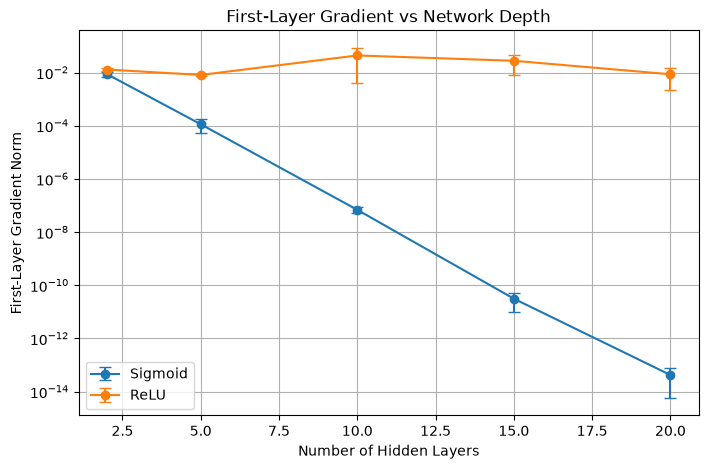

In [20]:
plt.figure(figsize=(8, 5))

sig_first_mean = [
    r["first_grad_mean"]
    for r in results["sigmoid"]
]

sig_first_std = [
    r["first_grad_std"]
    for r in results["sigmoid"]
]

relu_first_mean = [
    r["first_grad_mean"]
    for r in results["relu"]
]

relu_first_std = [
    r["first_grad_std"]
    for r in results["relu"]
]

plt.errorbar(
    depths,
    sig_first_mean,
    yerr=sig_first_std,
    marker="o",
    capsize=4,
    label="Sigmoid"
)

plt.errorbar(
    depths,
    relu_first_mean,
    yerr=relu_first_std,
    marker="o",
    capsize=4,
    label="ReLU"
)

plt.yscale("log")

plt.xlabel("Number of Hidden Layers")
plt.ylabel("First-Layer Gradient Norm")
plt.title("First-Layer Gradient vs Network Depth")

plt.legend()
plt.grid(True)

plt.show()

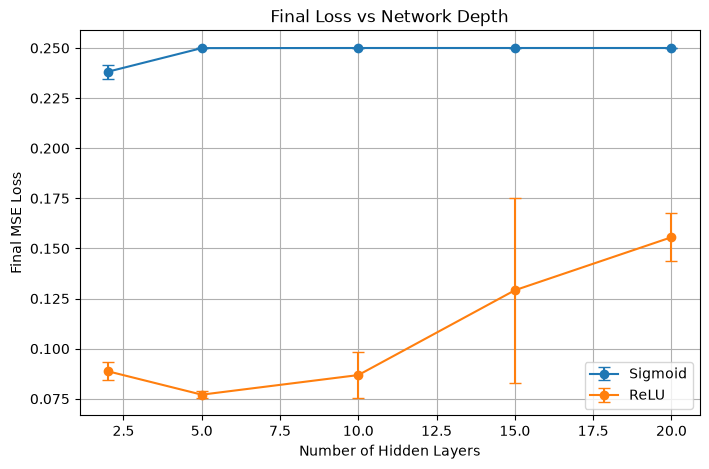

In [21]:
plt.figure(figsize=(8, 5))

sig_loss_mean = [
    r["loss_mean"]
    for r in results["sigmoid"]
]

sig_loss_std = [
    r["loss_std"]
    for r in results["sigmoid"]
]

relu_loss_mean = [
    r["loss_mean"]
    for r in results["relu"]
]

relu_loss_std = [
    r["loss_std"]
    for r in results["relu"]
]

plt.errorbar(
    depths,
    sig_loss_mean,
    yerr=sig_loss_std,
    marker="o",
    capsize=4,
    label="Sigmoid"
)

plt.errorbar(
    depths,
    relu_loss_mean,
    yerr=relu_loss_std,
    marker="o",
    capsize=4,
    label="ReLU"
)

plt.xlabel("Number of Hidden Layers")
plt.ylabel("Final MSE Loss")
plt.title("Final Loss vs Network Depth")

plt.legend()
plt.grid(True)

plt.show()

In [22]:
# Part 7A: Activation derivative statistics

def derivative_statistics(
    act_name,
    layer_sizes,
    X,
    seed=42
):

    np.random.seed(seed)

    act, act_prime = ACTIVATIONS[act_name]

    Ws, bs = init_weights(
        layer_sizes,
        act_name
    )

    hs, zs = forward(
        X,
        Ws,
        bs,
        act
    )

    derivative_means = []
    derivative_stds = []
    derivative_nonzero = []

    # Hidden layers only
    for k in range(len(Ws) - 1):

        z = zs[k]

        d = act_prime(z)

        derivative_means.append(
            np.mean(np.abs(d))
        )

        derivative_stds.append(
            np.std(d)
        )

        derivative_nonzero.append(
            np.mean(d != 0)
        )

    return (
        np.array(derivative_means),
        np.array(derivative_stds),
        np.array(derivative_nonzero)
    )

In [23]:
# Part 7B

part7_layer_sizes = [2] + [16] * 10 + [1]

for name in ["sigmoid", "relu"]:

    means, stds, nonzero = derivative_statistics(
        name,
        part7_layer_sizes,
        X,
        seed=42
    )

    print("\n" + "=" * 60)
    print(name.upper(), "ACTIVATION")
    print("=" * 60)

    for i in range(10):

        print(
            f"Layer {i+1:2d}: "
            f"mean |f'(z)| = {means[i]:.6e}, "
            f"std = {stds[i]:.6e}, "
            f"nonzero = {nonzero[i]:.4f}"
        )


SIGMOID ACTIVATION
Layer  1: mean |f'(z)| = 2.223797e-01, std = 3.833255e-02, nonzero = 1.0000
Layer  2: mean |f'(z)| = 2.345795e-01, std = 1.789241e-02, nonzero = 1.0000
Layer  3: mean |f'(z)| = 2.390048e-01, std = 1.178699e-02, nonzero = 1.0000
Layer  4: mean |f'(z)| = 2.353558e-01, std = 1.743583e-02, nonzero = 1.0000
Layer  5: mean |f'(z)| = 2.359554e-01, std = 1.482651e-02, nonzero = 1.0000
Layer  6: mean |f'(z)| = 2.260114e-01, std = 2.757823e-02, nonzero = 1.0000
Layer  7: mean |f'(z)| = 2.420338e-01, std = 9.482491e-03, nonzero = 1.0000
Layer  8: mean |f'(z)| = 2.365752e-01, std = 1.868093e-02, nonzero = 1.0000
Layer  9: mean |f'(z)| = 2.345355e-01, std = 1.387659e-02, nonzero = 1.0000
Layer 10: mean |f'(z)| = 2.299164e-01, std = 2.895149e-02, nonzero = 1.0000

RELU ACTIVATION
Layer  1: mean |f'(z)| = 4.445000e-01, std = 4.969102e-01, nonzero = 0.4445
Layer  2: mean |f'(z)| = 4.327500e-01, std = 4.954568e-01, nonzero = 0.4328
Layer  3: mean |f'(z)| = 4.588750e-01, std = 4.9830

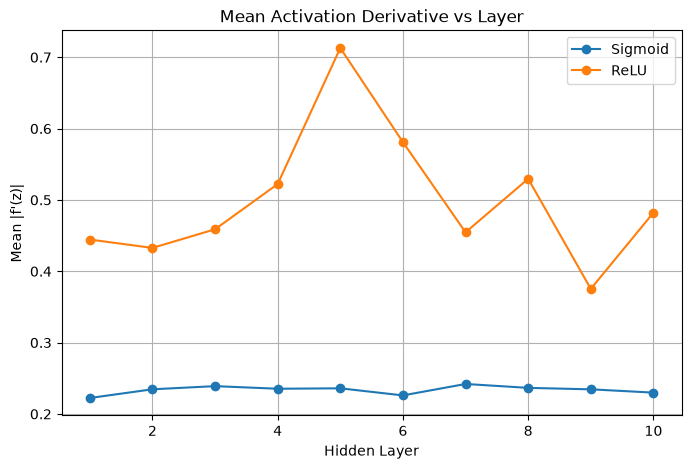

In [24]:
# Part 7C

part7_layer_sizes = [2] + [16] * 10 + [1]

sig_means, sig_stds, sig_nonzero = derivative_statistics(
    "sigmoid",
    part7_layer_sizes,
    X,
    seed=42
)

relu_means, relu_stds, relu_nonzero = derivative_statistics(
    "relu",
    part7_layer_sizes,
    X,
    seed=42
)

layers = np.arange(1, 11)

plt.figure(figsize=(8, 5))

plt.plot(
    layers,
    sig_means,
    marker="o",
    label="Sigmoid"
)

plt.plot(
    layers,
    relu_means,
    marker="o",
    label="ReLU"
)

plt.xlabel("Hidden Layer")
plt.ylabel("Mean |f'(z)|")
plt.title("Mean Activation Derivative vs Layer")

plt.legend()
plt.grid(True)

plt.show()

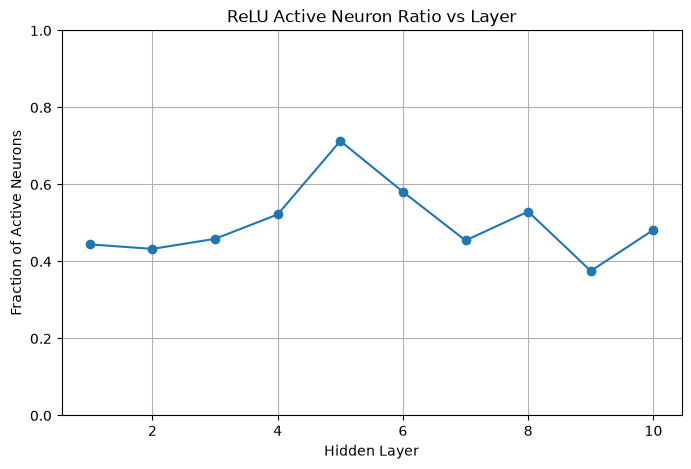

In [25]:
# Part 7D

plt.figure(figsize=(8, 5))

plt.plot(
    layers,
    relu_nonzero,
    marker="o"
)

plt.xlabel("Hidden Layer")
plt.ylabel("Fraction of Active Neurons")
plt.title("ReLU Active Neuron Ratio vs Layer")

plt.ylim(0, 1)

plt.grid(True)

plt.show()

In [26]:
# Part 7E: Cumulative derivative product

part7_layer_sizes = [2] + [16] * 10 + [1]

sig_means, _, _ = derivative_statistics(
    "sigmoid",
    part7_layer_sizes,
    X,
    seed=42
)

relu_means, _, _ = derivative_statistics(
    "relu",
    part7_layer_sizes,
    X,
    seed=42
)

sigmoid_product = np.cumprod(
    sig_means
)

relu_product = np.cumprod(
    relu_means
)

layers = np.arange(1, 11)

print("Sigmoid cumulative product:")
print(sigmoid_product)

print("\nReLU cumulative product:")
print(relu_product)

Sigmoid cumulative product:
[2.22379693e-01 5.21657246e-02 1.24678607e-02 2.93438354e-03
 6.92383536e-04 1.56486558e-04 3.78750410e-05 8.96029502e-06
 2.10150689e-06 4.83170845e-07]

ReLU cumulative product:
[0.4445     0.19235738 0.08826799 0.04609796 0.03286784 0.01909622
 0.00868162 0.004598   0.00172597 0.00083214]


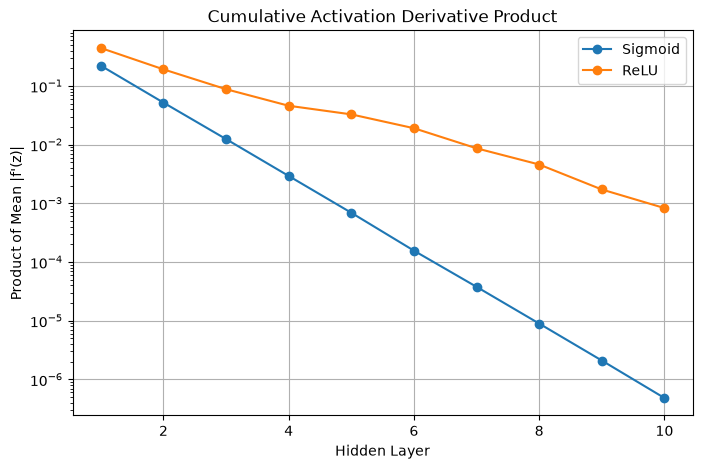

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(
    layers,
    sigmoid_product,
    marker="o",
    label="Sigmoid"
)

plt.plot(
    layers,
    relu_product,
    marker="o",
    label="ReLU"
)

plt.yscale("log")

plt.xlabel("Hidden Layer")
plt.ylabel("Product of Mean |f'(z)|")

plt.title(
    "Cumulative Activation Derivative Product"
)

plt.legend()
plt.grid(True)

plt.show()

In [38]:
# Part 9A: Exploding Gradient / Jacobian Product

def exploding_jacobian_experiment(
    depth,
    width=16,
    scale=1.5,
    x=None,
    seed=42
):

    np.random.seed(seed)

    if x is None:
        x = X[0:1]

    h = x.copy()

    layer_norms = []
    cumulative_norms = []

    J_product = None

    for layer in range(depth):

        # Input dimension of this layer
        input_dim = h.shape[1]

        # Weight matrix
        W = np.random.randn(
            input_dim,
            width
        ) * scale

        # Bias
        b = np.zeros(
            (1, width)
        )

        # Forward propagation
        z = h @ W + b

        # ReLU derivative
        derivative = relu_prime(z[0])

        # Diagonal activation derivative matrix
        D = np.diag(derivative)

        # IMPORTANT:
        # Since forward is h @ W,
        # the Jacobian is D @ W.T
        J = D @ W.T

        # Spectral norm
        J_norm = np.linalg.norm(
            J,
            ord=2
        )

        layer_norms.append(J_norm)

        # --------------------------------
        # Jacobian product
        # --------------------------------

        if layer == 0:

            # J1: (16, 2)
            J_product = J.copy()

        else:

            # Jk: (16, 16)
            #
            # J2 @ J1
            # J3 @ J2 @ J1
            # ...
            J_product = J @ J_product

        # Norm of cumulative Jacobian
        cumulative_norm = np.linalg.norm(
            J_product,
            ord=2
        )

        cumulative_norms.append(
            cumulative_norm
        )

        # Next activation
        h = relu(z)

    return (
        np.array(layer_norms),
        np.array(cumulative_norms)
    )

In [39]:
# Part 9B

depth = 20

layer_norms, cumulative_norms = (
    exploding_jacobian_experiment(
        depth=depth,
        width=16,
        scale=1.5,
        x=X[0:1],
        seed=42
    )
)

print("Layer Jacobian norms:")
print(layer_norms)

print("\nCumulative Jacobian product norms:")
print(cumulative_norms)

Layer Jacobian norms:
[ 4.95606083  9.44217592  9.69748315 10.19514661 10.3960046  10.28563148
  9.22119624  9.29260707  7.62842832  8.24395364  8.11626328  8.78444186
 10.76567745  8.69746923  9.16745421  9.43328471 10.17249291  7.86589625
  9.86568526  7.9166942 ]

Cumulative Jacobian product norms:
[4.95606083e+00 1.42764850e+01 5.89621007e+01 3.50391783e+02
 1.93552681e+03 1.07977504e+04 3.94979085e+04 1.44985418e+05
 7.17789600e+05 3.82045071e+06 1.35676770e+07 6.23561692e+07
 2.49519406e+08 8.72122632e+08 5.60083855e+09 2.40490559e+10
 1.02159915e+11 5.03971115e+11 2.24565701e+12 9.88850843e+12]


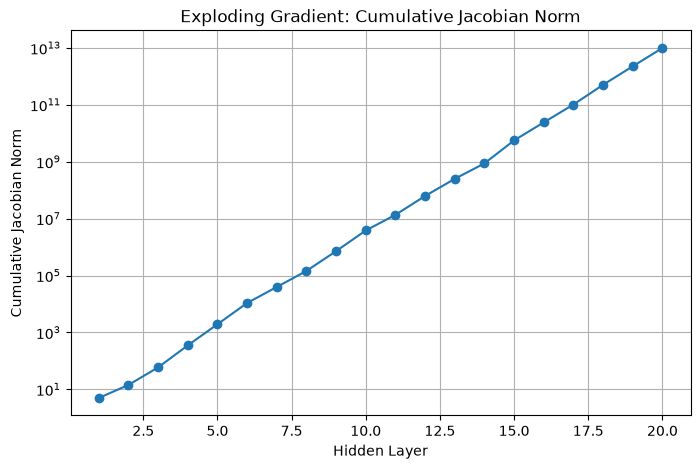

In [40]:
# Part 9C: Plot cumulative Jacobian norm

layers = np.arange(1, depth + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    layers,
    cumulative_norms,
    marker="o"
)

plt.yscale("log")

plt.xlabel("Hidden Layer")
plt.ylabel("Cumulative Jacobian Norm")

plt.title(
    "Exploding Gradient: Cumulative Jacobian Norm"
)

plt.grid(True)

plt.show()

In [42]:
# Part 9D: Compare different weight scales

scales = [0.1, 0.5, 1.0, 1.5]

depth = 20

scale_results = {}

for scale in scales:

    _, cumulative = exploding_jacobian_experiment(
        depth=depth,
        width=16,
        scale=scale,
        x=X[0:1],
        seed=42
    )

    scale_results[scale] = cumulative

    print(
        f"Scale = {scale}: "
        f"final cumulative norm = "
        f"{cumulative[-1]:.6e}"
    )

Scale = 0.1: final cumulative norm = 2.973758e-11
Scale = 0.5: final cumulative norm = 2.835997e+03
Scale = 1.0: final cumulative norm = 2.973758e+09
Scale = 1.5: final cumulative norm = 9.888508e+12


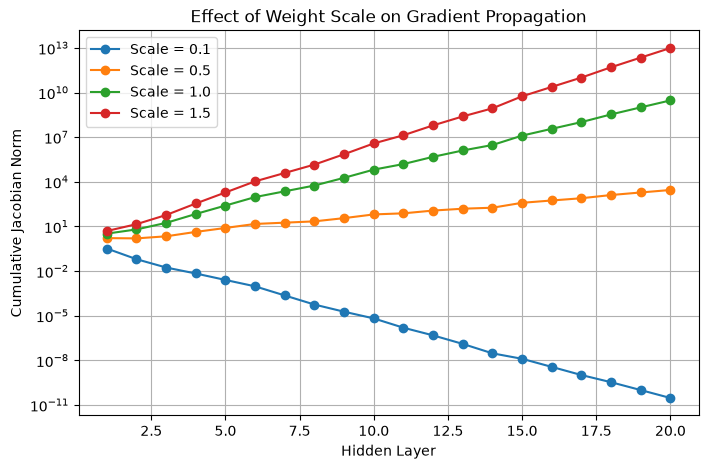

In [43]:
# Part 9E: Plot different weight scales

layers = np.arange(1, depth + 1)

plt.figure(figsize=(8, 5))

for scale in scales:

    plt.plot(
        layers,
        scale_results[scale],
        marker="o",
        label=f"Scale = {scale}"
    )

plt.yscale("log")

plt.xlabel("Hidden Layer")
plt.ylabel("Cumulative Jacobian Norm")

plt.title(
    "Effect of Weight Scale on Gradient Propagation"
)

plt.legend()
plt.grid(True)

plt.show()